# 02 – Digester batch analysis (D1–D4)

Reads only `data/batch_master.csv` and `data/lab_linked.csv` (made by `01_build_master.ipynb`) – fast, no PI access.
The order follows `workflow.md`: **baseline quality → Step 1 chips → Step 2 prehydrolysis → Step 3 heat & cook → Step 4 displacement → link to lab**.

Settings at the top: `ONLY_OK_BATCHES` (use only batches with `quality_flag == "ok"`).

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import config

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 80)

from build_master import load_outputs

ONLY_OK_BATCHES = True

master, lab_linked = load_outputs()
if ONLY_OK_BATCHES:
    master = master[master["quality_flag"] == "ok"]
print("Batches:", len(master), "| per digester:", master["digester"].value_counts().sort_index().to_dict())

LAB_LABELS = {"press1_kappa": "Kappa", "press1_viscosity": "Viscosity", "press1_brightness": "Brightness"}


def volatility_table(columns):
    """N, Mean, SD, CV%, Min, Max per digester for each column."""
    rows = []
    for col in columns:
        if col not in master:
            continue
        for dig, vals in master.groupby("digester")[col]:
            vals = vals.dropna()
            rows.append({"Parameter": col, "Digester": f"D{dig}", "N": len(vals), "Mean": vals.mean(),
                         "SD": vals.std(), "CV%": 100 * vals.std() / vals.mean() if vals.mean() else np.nan,
                         "Min": vals.min(), "Max": vals.max()})
    return pd.DataFrame(rows).set_index(["Parameter", "Digester"]).round(2)


def boxplots(columns, title):
    """One boxplot per column, D1-D4 side by side."""
    columns = [c for c in columns if c in master]
    fig, axes = plt.subplots(1, len(columns), figsize=(4.5 * len(columns), 4.5))
    for ax, col in zip(np.atleast_1d(axes), columns):
        sns.boxplot(data=master, x="digester", y=col, ax=ax)
        ax.set_title(col, fontsize=9)
        ax.set_xlabel("Digester")
        ax.set_ylabel("")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

Batches: 904 | per digester: {1: 249, 2: 252, 3: 245, 4: 158}


## Phase 1 – Baseline: Press 1 lab quality per digester

Real lab samples only. Green band = SOP (`config.LAB_SOP_LIMITS`, **not yet confirmed**).

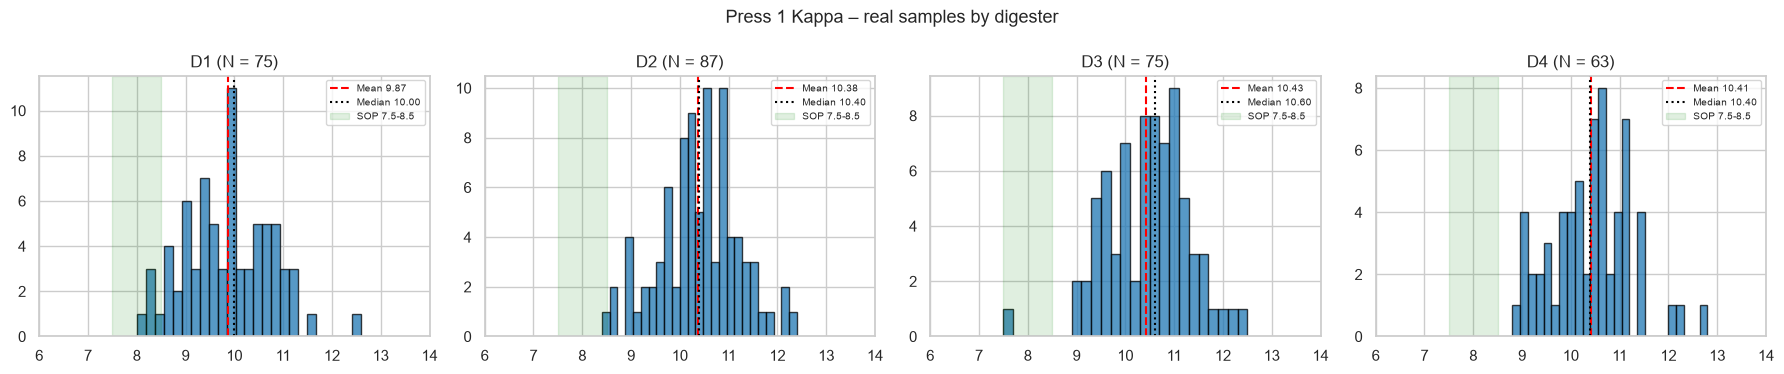

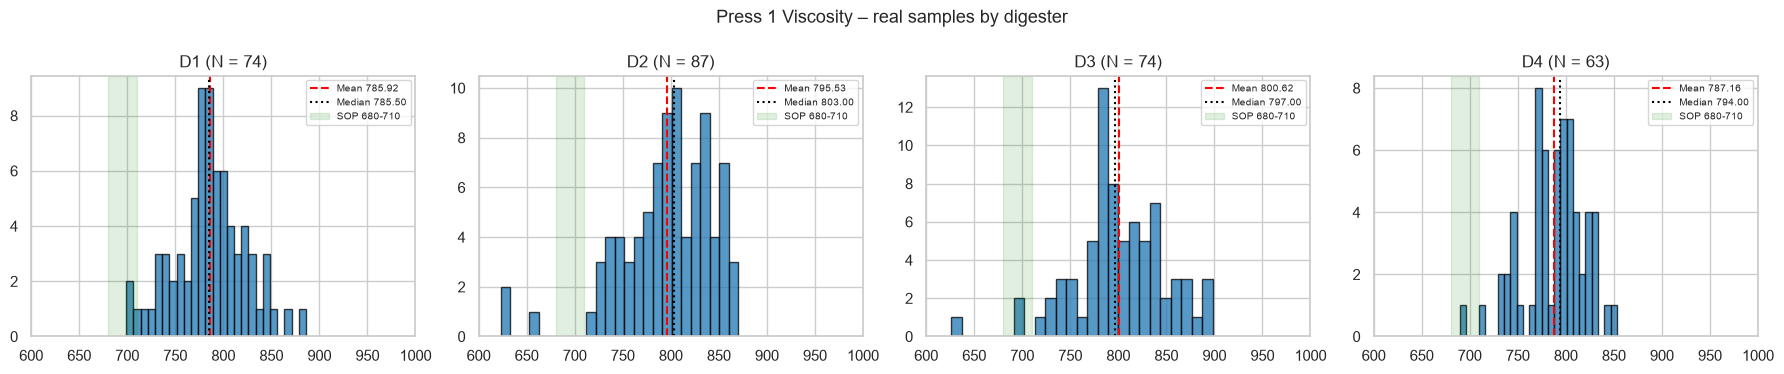

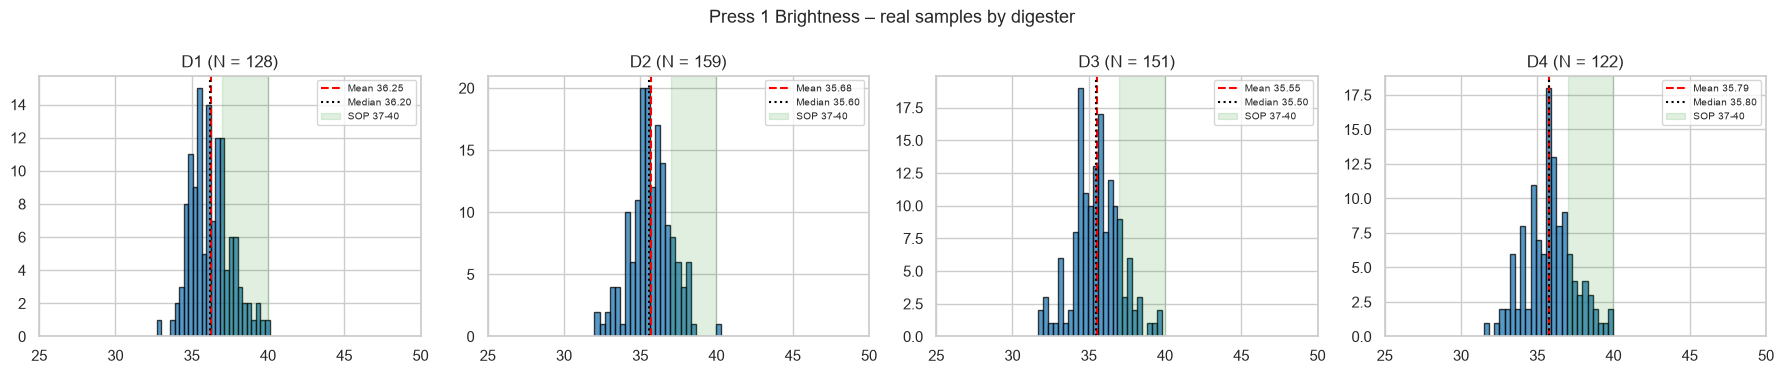

N    Mean  Median     SD
parameter         digester                            
press1_brightness 1         128   36.25    36.2   1.35
                  2         159   35.68    35.6   1.36
                  3         151   35.55    35.5   1.53
                  4         122   35.79    35.8   1.63
press1_kappa      1          75    9.87    10.0   0.89
                  2          87   10.38    10.4   0.82
                  3          75   10.43    10.6   0.85
                  4          63   10.41    10.4   0.83
press1_viscosity  1          74  785.92   785.5  37.20
                  2          87  795.53   803.0  48.95
                  3          74  800.62   797.0  48.77
                  4          63  787.16   794.0  32.48

In [2]:
HIST_XLIM = {"press1_kappa": (6, 14), "press1_viscosity": (600, 1000), "press1_brightness": (25, 50)}

for param, label in LAB_LABELS.items():
    data = lab_linked[lab_linked["parameter"] == param]
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharex=True)
    for ax, dig in zip(axes, [1, 2, 3, 4]):
        vals = data.loc[data["digester"] == dig, "value"].dropna()
        ax.hist(vals, bins=25, color="#1f77b4", edgecolor="black", alpha=0.75)
        ax.axvline(vals.mean(), color="red", linestyle="--", label=f"Mean {vals.mean():.2f}")
        ax.axvline(vals.median(), color="black", linestyle=":", label=f"Median {vals.median():.2f}")
        lo, hi = config.LAB_SOP_LIMITS[param]
        ax.axvspan(lo, hi, color="green", alpha=0.12, label=f"SOP {lo}-{hi}")
        ax.set_xlim(HIST_XLIM[param])
        ax.set_title(f"D{dig} (N = {len(vals)})")
        ax.legend(fontsize=7)
    fig.suptitle(f"Press 1 {label} – real samples by digester", fontsize=13)
    plt.tight_layout()
    plt.show()

summary = (lab_linked.groupby(["parameter", "digester"])["value"]
           .agg(N="count", Mean="mean", Median="median", SD="std").round(2))
display(summary)

### Lab trend over time (24 h rolling mean)

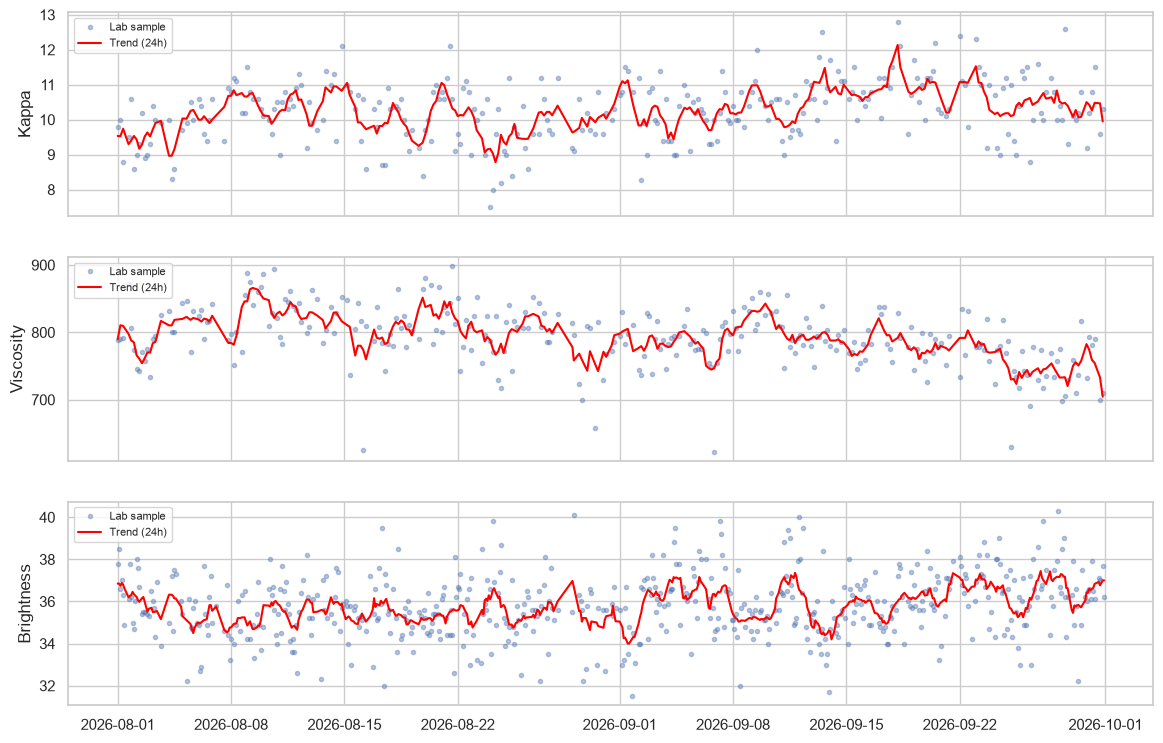

In [3]:
TREND_WINDOW = "24h"

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, (param, label) in zip(axes, LAB_LABELS.items()):
    s = (lab_linked[lab_linked["parameter"] == param]
         .drop_duplicates("timestamp").set_index("timestamp")["value"].sort_index().dropna())
    ax.plot(s.index, s, ".", alpha=0.4, label="Lab sample")
    ax.plot(s.index, s.rolling(TREND_WINDOW, center=True, min_periods=1).mean(), color="red",
            label=f"Trend ({TREND_WINDOW})")
    ax.set_ylabel(label)
    ax.legend(fontsize=8, loc="upper left")
plt.show()

## Step 1 – Input & preparation (chips)

- `chip_weight_max_chip_filling` – chips loaded (wet weight, ton; chip moisture tag is not usable)
- `liquor_to_wood_ratio` – liquor added per ton of wet chips (approximate L:W)
- `white_liquor_m3`, `white_liquor_per_ton_chip` – white liquor added in HOT LIQUOR FILLING, and per ton of wet chips (same recipe volume + fewer chips = more alkali per ton)
- `ventilation_temp_max_chip_filling`, `chip_filling_minutes`

N   Mean     SD    CV%    Min  \
Parameter                         Digester                                    
chip_weight_max_chip_filling      D1        249  92.96   6.22   6.70  76.01   
                                  D2        252  94.89   4.81   5.07  82.09   
                                  D3        245  87.15   7.03   8.07  59.72   
                                  D4        158  71.97   5.33   7.41  50.01   
liquor_to_wood_ratio              D1        249   1.52   0.17  10.95   1.02   
                                  D2        252   1.44   0.12   8.46   1.13   
                                  D3        245   1.76   0.25  13.96   1.26   
                                  D4        158   1.58   0.21  13.22   1.09   
white_liquor_m3                   D1        249  13.39   1.70  12.69  10.20   
                                  D2        252  13.13   1.41  10.74  10.11   
                                  D3        245  13.62   2.06  15.15  11.75   
                                  D4        158  13.45   1.61  11.99  11.84   
white_liquor_per_ton_chip         D1        249   0.14   0.02  14.02   0.10   
                                  D2        252   0.14   0.02  11.56   0.10   
                                  D3        245   0.16   0.03  16.10   0.12   
                                  D4        158   0.19   0.02  11.56   0.15   
ventilation_temp_max_chip_filling D1        249  90.18   2.21   2.46  85.00   
                                  D2        252  93.89   2.13   2.27  86.46   
                                  D3        245  91.30   2.54   2.78  79.58   
                                  D4        158  90.04   1.72   1.91  75.66   
chip_filling_minutes              D1        249  35.20   9.45  26.84  30.00   
                                  D2        252  36.98  15.47  41.82  20.00   
                                  D3        245  36.02  24.14  67.01  25.00   
                                  D4        158  34.56   7.06  20.42  20.00   

                                               Max  
Parameter                         Digester          
chip_weight_max_chip_filling      D1        115.25  
                                  D2        110.59  
                                  D3        106.99  
                                  D4         89.11  
liquor_to_wood_ratio              D1          1.98  
                                  D2          1.85  
                                  D3          3.02  
                                  D4          2.66  
white_liquor_m3                   D1         21.93  
                                  D2         22.93  
                                  D3         24.94  
                                  D4         24.92  
white_liquor_per_ton_chip         D1          0.24  
                                  D2          0.24  
                                  D3          0.30  
                                  D4          0.31  
ventilation_temp_max_chip_filling D1         96.74  
                                  D2        100.53  
                                  D3         99.33  
                                  D4         97.61  
chip_filling_minutes              D1        110.00  
                                  D2        235.00  
                                  D3        385.00  
                                  D4         65.00

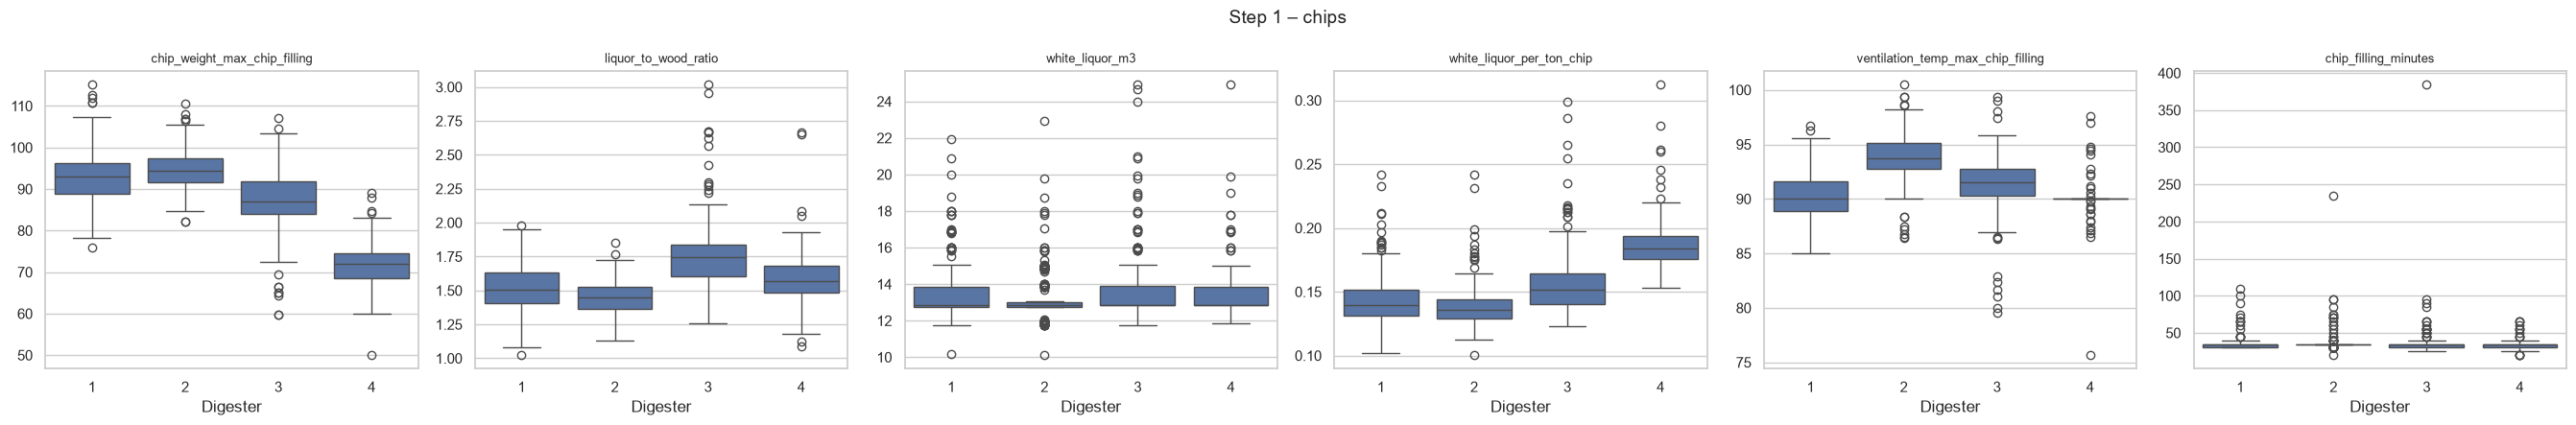

In [4]:
STEP1 = ["chip_weight_max_chip_filling", "liquor_to_wood_ratio",
         "white_liquor_m3", "white_liquor_per_ton_chip", "ventilation_temp_max_chip_filling", "chip_filling_minutes"]
display(volatility_table(STEP1))
boxplots(STEP1, "Step 1 – chips")

## Step 2 – Prehydrolysis

- `pfactor_actual_last_prehydrolysis` vs `pfactor_setpoint_last_prehydrolysis`; `pfactor_gap` = actual − setpoint
- `digester_pressure_max_prehydrolysis`, `prehydrolysis_minutes`

N    Mean     SD    CV%  \
Parameter                           Digester                              
pfactor_actual_last_prehydrolysis   D1        249  339.09  23.59   6.96   
                                    D2        252  347.63  20.62   5.93   
                                    D3        245  345.82  22.55   6.52   
                                    D4        158  353.32  21.15   5.98   
pfactor_setpoint_last_prehydrolysis D1        249  364.38  18.81   5.16   
                                    D2        252  364.29  18.76   5.15   
                                    D3        245  364.33  18.97   5.21   
                                    D4        158  371.71  19.29   5.19   
pfactor_gap                         D1        249  -25.29  15.64 -61.83   
                                    D2        252  -16.66  11.62 -69.74   
                                    D3        245  -18.51  13.48 -72.84   
                                    D4        158  -18.39  10.51 -57.16   
digester_pressure_max_prehydrolysis D1        249    8.38   0.44   5.20   
                                    D2        252    8.29   0.20   2.45   
                                    D3        245    8.36   0.35   4.23   
                                    D4        158    8.02   0.51   6.31   
prehydrolysis_minutes               D1        249   76.91   9.57  12.45   
                                    D2        252   84.42   8.17   9.67   
                                    D3        245   81.24  14.04  17.28   
                                    D4        158   86.90   9.09  10.46   

                                                 Min     Max  
Parameter                           Digester                  
pfactor_actual_last_prehydrolysis   D1        292.94  417.61  
                                    D2        309.44  420.04  
                                    D3        292.78  419.34  
                                    D4        311.37  419.51  
pfactor_setpoint_last_prehydrolysis D1        320.00  430.00  
                                    D2        320.00  430.00  
                                    D3        320.00  430.00  
                                    D4        340.00  430.00  
pfactor_gap                         D1        -59.65    1.59  
                                    D2        -72.84    0.74  
                                    D3        -50.09    0.64  
                                    D4        -39.96   -0.05  
digester_pressure_max_prehydrolysis D1          7.10   11.06  
                                    D2          7.25    9.77  
                                    D3          7.18   10.14  
                                    D4          7.15    8.94  
prehydrolysis_minutes               D1         60.00  120.00  
                                    D2         55.00  120.00  
                                    D3         65.00  270.00  
                                    D4         70.00  115.00

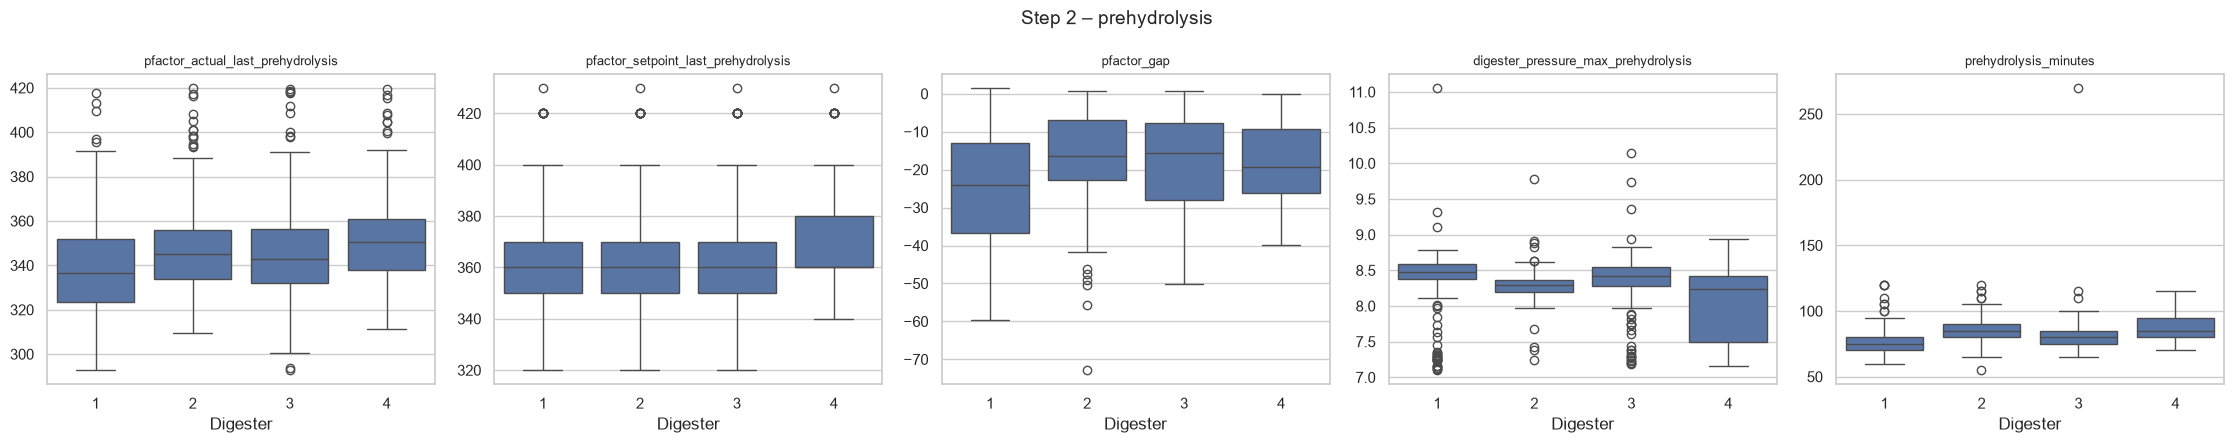

In [5]:
STEP2 = ["pfactor_actual_last_prehydrolysis", "pfactor_setpoint_last_prehydrolysis", "pfactor_gap",
         "digester_pressure_max_prehydrolysis", "prehydrolysis_minutes"]
display(volatility_table(STEP2))
boxplots(STEP2, "Step 2 – prehydrolysis")

## Step 3 – Heat & cook

- `h_factor` (phases in `config.H_FACTOR_PHASES`) and `h_heat_and_cook` (HEAT&COOK only, for comparison)
- temperatures, steam, pressure, and circulation health (screen ΔP, pump current)

N    Mean      SD  \
Parameter                                   Digester                        
h_factor                                    D1        249  507.36   90.97   
                                            D2        252  365.01  105.80   
                                            D3        245  308.47   57.13   
                                            D4        158  406.35  126.73   
h_heat_and_cook                             D1        249  158.98   21.48   
                                            D2        252  167.49   17.14   
                                            D3        245  169.31   13.74   
                                            D4        158  171.42   17.03   
circulation_temp_max_heat_and_cook          D1        249  157.44    1.61   
                                            D2        252  159.34    1.06   
                                            D3        245  157.73    1.35   
                                            D4        158  158.57    1.13   
heat_and_cook_minutes                       D1        249   37.07    5.89   
                                            D2        252   30.06    6.76   
                                            D3        245   34.55    5.53   
                                            D4        158   36.04    4.45   
steam_to_heater_flow_mean_heat_and_cook     D1        249    3.27    3.74   
                                            D2        252    2.71    1.50   
                                            D3        245    0.70    1.73   
                                            D4        158   20.59    1.97   
screen_diff_pressure_mean_heat_and_cook     D1        249   -1.87    0.00   
                                            D2        252   -0.25    0.00   
                                            D3        245   -0.25    0.00   
                                            D4          0     NaN     NaN   
circulation_pump_current_mean_heat_and_cook D1        249   65.10    4.27   
                                            D2        252   64.19    5.95   
                                            D3        245   66.17    5.06   
                                            D4        158   63.48    4.38   

                                                         CV%     Min      Max  
Parameter                                   Digester                           
h_factor                                    D1         17.93  301.17  1342.93  
                                            D2         28.99  198.93   911.93  
                                            D3         18.52  241.32   622.39  
                                            D4         31.19  205.44   840.24  
h_heat_and_cook                             D1         13.51  111.69   296.40  
                                            D2         10.24  127.61   259.51  
                                            D3          8.11  137.56   207.67  
                                            D4          9.94  124.99   217.55  
circulation_temp_max_heat_and_cook          D1          1.02  154.04   163.99  
                                            D2          0.67  153.61   162.42  
                                            D3          0.85  154.65   163.36  
                                            D4          0.71  155.55   162.01  
heat_and_cook_minutes                       D1         15.90   15.00    95.00  
                                            D2         22.49   20.00   115.00  
                                            D3         15.99   15.00    55.00  
                                            D4         12.33   25.00    55.00  
steam_to_heater_flow_mean_heat_and_cook     D1        114.37   -5.87    11.77  
                                            D2         55.28   -2.39     6.35  
                                            D3        248.33   -3.14     4.42  
                                            D4          9.57   -0

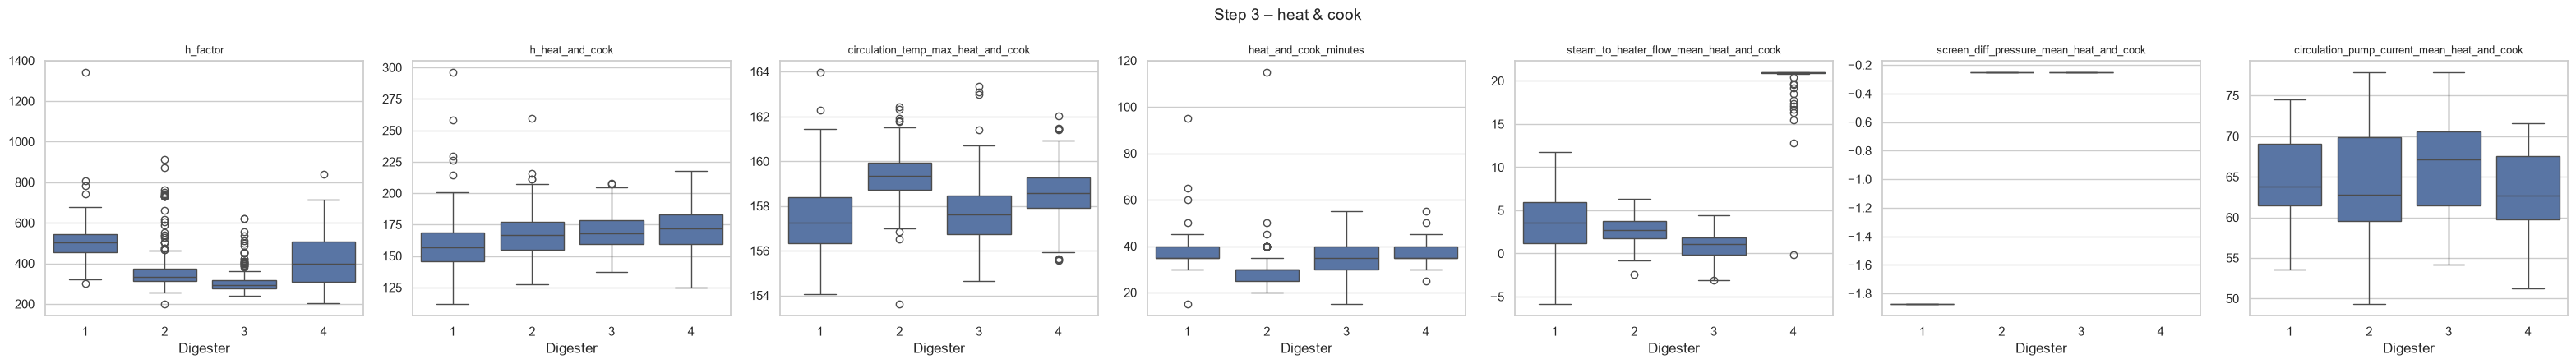

In [6]:
STEP3 = ["h_factor", "h_heat_and_cook", "circulation_temp_max_heat_and_cook", "heat_and_cook_minutes",
         "steam_to_heater_flow_mean_heat_and_cook", "screen_diff_pressure_mean_heat_and_cook",
         "circulation_pump_current_mean_heat_and_cook"]
display(volatility_table(STEP3))
boxplots(STEP3, "Step 3 – heat & cook")

## Step 4 – Displacement

- `displacement_liquor_temp_mean_displacement`, `displacement_minutes`, `h_displacement` (cooking still going on)
- `black_liquor_conductivity_mean_displacement` (shared tag, residual-alkali proxy)

N    Mean     SD  \
Parameter                                   Digester                       
displacement_liquor_temp_mean_displacement  D1        249  133.74   6.06   
                                            D2        252  132.89   5.20   
                                            D3        245  135.35   6.20   
                                            D4        158  134.81   6.20   
displacement_minutes                        D1        249   36.43  20.22   
                                            D2        252   30.58  17.00   
                                            D3        245   33.92   7.82   
                                            D4        158   38.32  26.19   
h_displacement                              D1        249   95.75  65.06   
                                            D2        252  103.37  52.01   
                                            D3        245   79.87  21.93   
                                            D4        158   81.32  39.01   
black_liquor_conductivity_mean_displacement D1        249   50.32   4.62   
                                            D2        252   52.20  14.67   
                                            D3        245   50.99   9.40   
                                            D4        158   50.14   6.05   

                                                        CV%     Min     Max  
Parameter                                   Digester                         
displacement_liquor_temp_mean_displacement  D1         4.53  111.64  147.88  
                                            D2         3.92  120.68  149.49  
                                            D3         4.58  114.61  151.23  
                                            D4         4.60  116.83  149.37  
displacement_minutes                        D1        55.50   20.00  255.00  
                                            D2        55.60   15.00  230.00  
                                            D3        23.07   15.00   70.00  
                                            D4        68.34   25.00  335.00  
h_displacement                              D1        67.94   44.90  962.01  
                                            D2        50.31   28.26  672.41  
                                            D3        27.46   32.04  208.46  
                                            D4        47.97   29.87  255.70  
black_liquor_conductivity_mean_displacement D1         9.17   49.54   88.41  
                                            D2        28.11   49.40  151.48  
                                            D3        18.44   49.40  151.33  
                                            D4        12.06   49.54  122.31

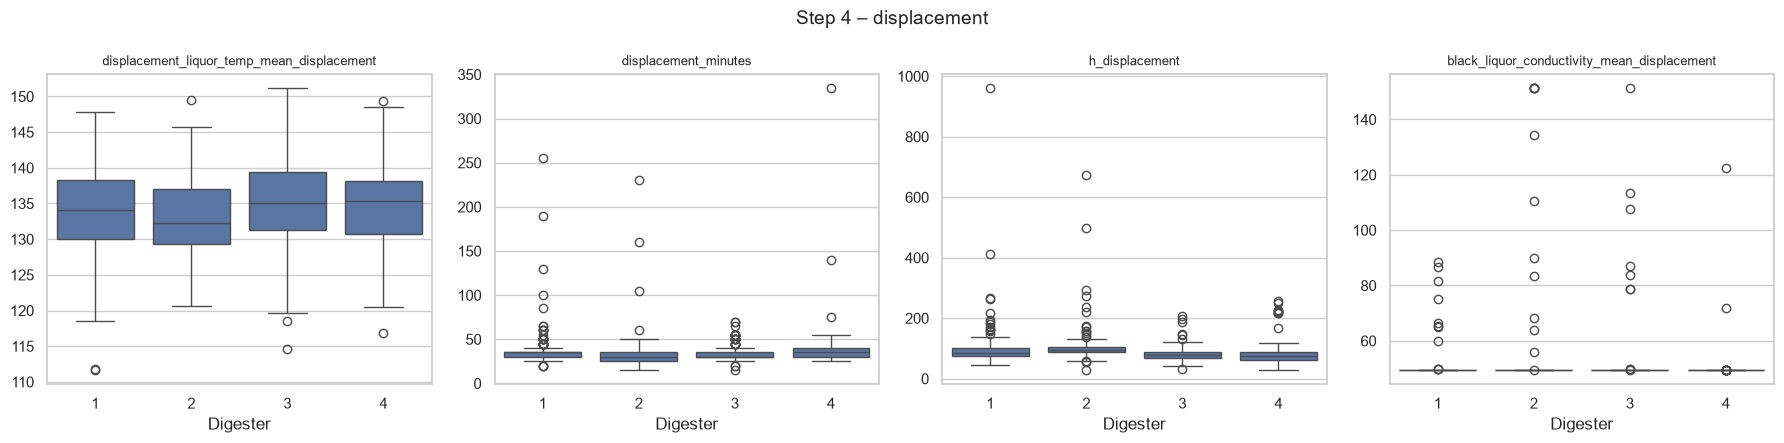

In [7]:
STEP4 = ["displacement_liquor_temp_mean_displacement", "displacement_minutes", "h_displacement",
         "black_liquor_conductivity_mean_displacement"]
display(volatility_table(STEP4))
boxplots(STEP4, "Step 4 – displacement")

## Phase 4 – Link to lab: which batch values go with Press 1 quality?

Only batches with a lab value. Spearman correlation per digester (rows = batch values, columns = lab).
Rough guide with ~60–85 batches per digester: |r| < 0.25 is likely noise.

D:\chinnput\DP Cooking ODL Analyzer\.venv\Lib\site-packages\pandas\core\nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
D:\chinnput\DP Cooking ODL Analyzer\.venv\Lib\site-packages\pandas\core\nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
D:\chinnput\DP Cooking ODL Analyzer\.venv\Lib\site-packages\pandas\core\nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


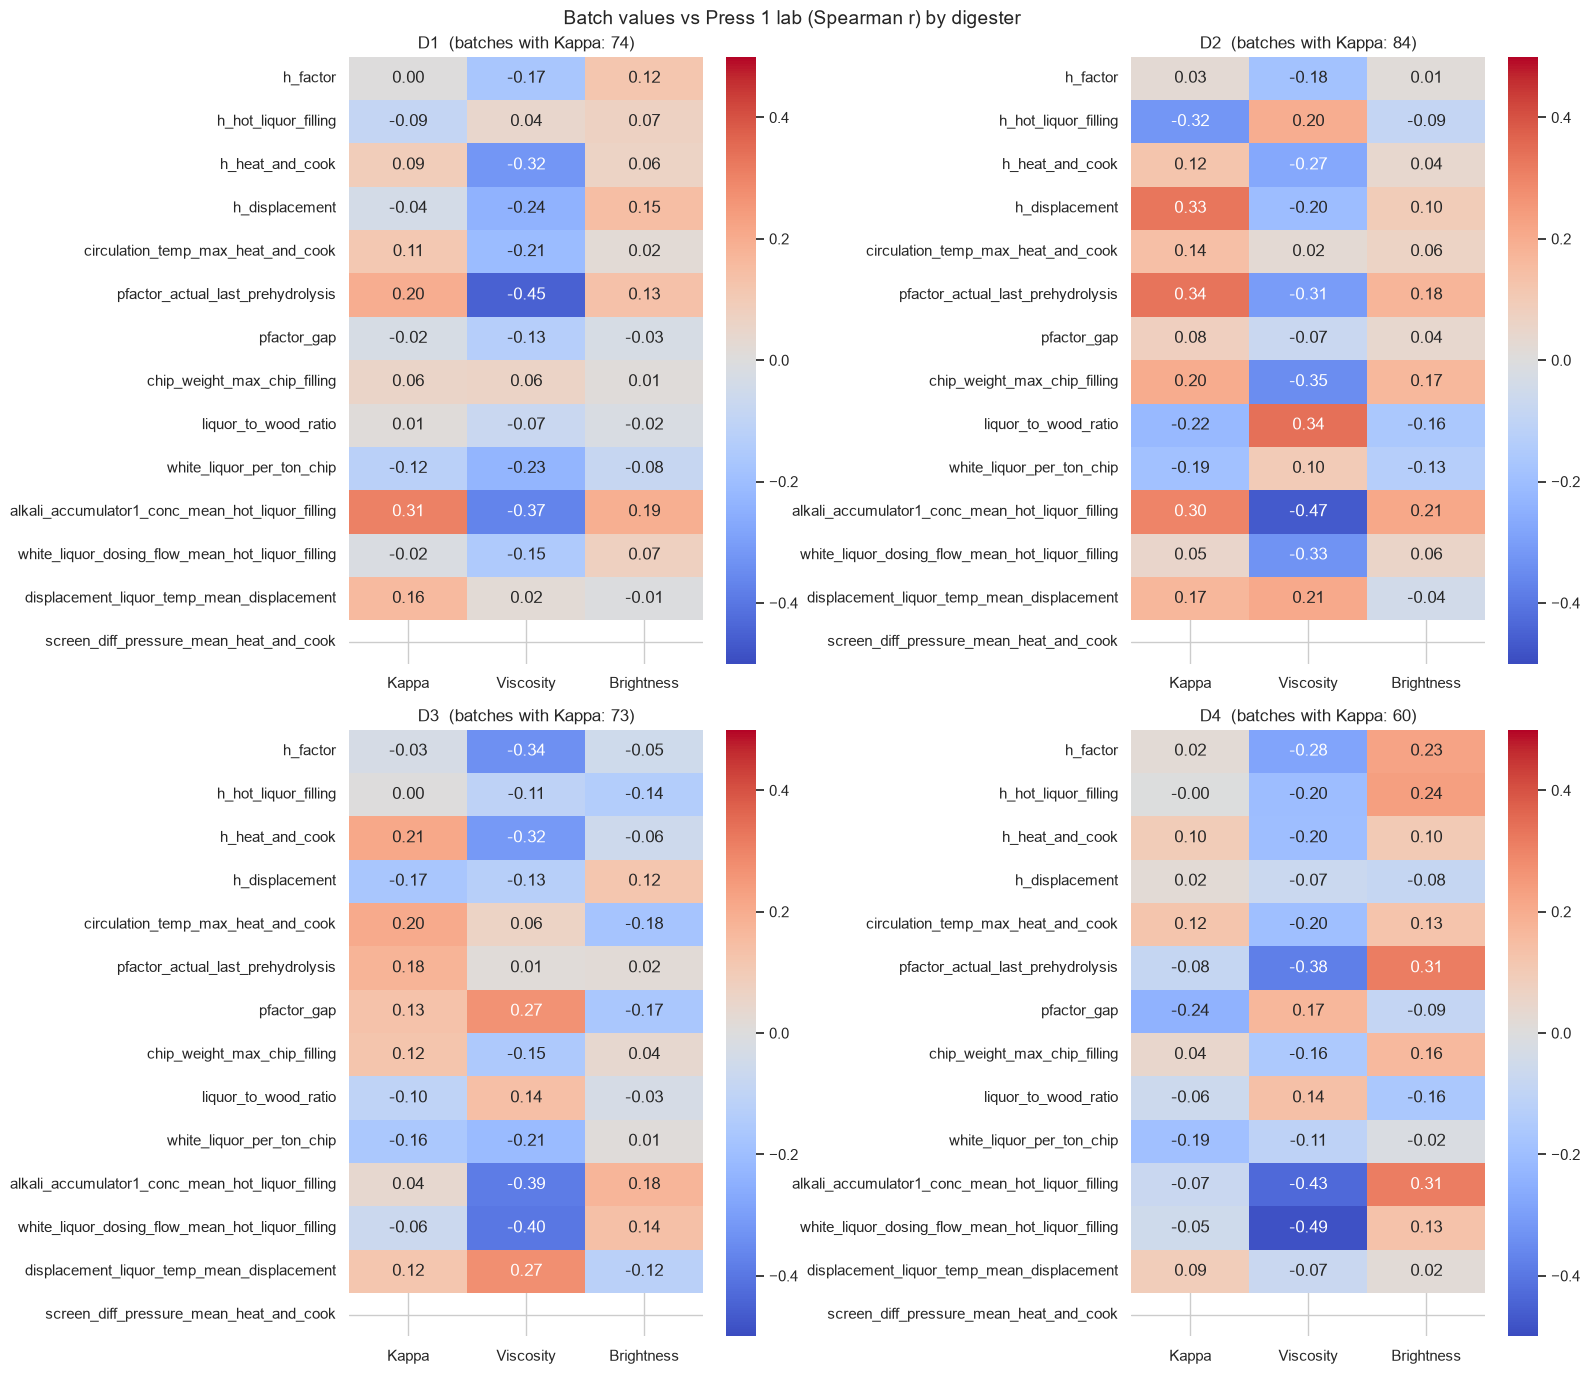

In [8]:
X_COLUMNS = ["h_factor", "h_hot_liquor_filling", "h_heat_and_cook", "h_displacement",
             "circulation_temp_max_heat_and_cook", "pfactor_actual_last_prehydrolysis", "pfactor_gap",
             "chip_weight_max_chip_filling", "liquor_to_wood_ratio", "white_liquor_per_ton_chip",
             "alkali_accumulator1_conc_mean_hot_liquor_filling", "white_liquor_dosing_flow_mean_hot_liquor_filling",
             "displacement_liquor_temp_mean_displacement", "screen_diff_pressure_mean_heat_and_cook"]
X_COLUMNS = [c for c in X_COLUMNS if c in master]
CORR_LIMIT = 0.5

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for ax, dig in zip(axes.flatten(), [1, 2, 3, 4]):
    d = master[master["digester"] == dig]
    corr = pd.DataFrame({label: [d[x].corr(d[param], method="spearman") for x in X_COLUMNS]
                         for param, label in LAB_LABELS.items()}, index=X_COLUMNS)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-CORR_LIMIT, vmax=CORR_LIMIT, ax=ax)
    ax.set_title(f"D{dig}  (batches with Kappa: {d['press1_kappa'].notna().sum()})")
plt.suptitle("Batch values vs Press 1 lab (Spearman r) by digester", fontsize=14)
plt.tight_layout()
plt.show()

### H-factor vs Kappa – which H-factor gives low Kappa?

1. Scatter with a straight trend line (dots going down to the right = more H gives lower Kappa).
2. H-factor in 5 equal-size groups per digester: the group with the lowest Kappa median.

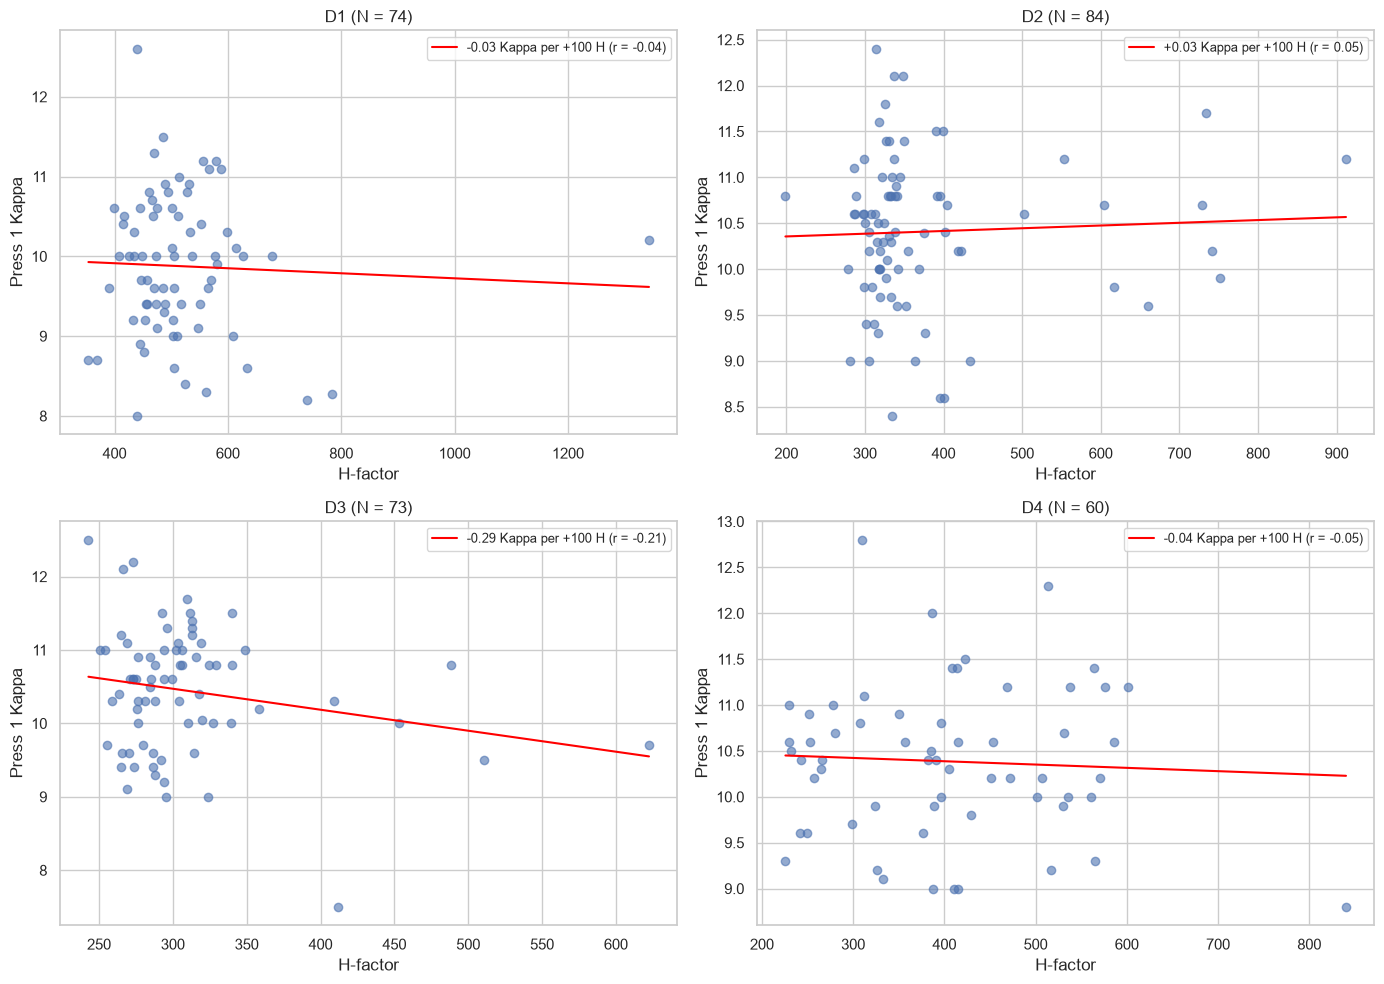

,Digester,H-factor range,Batches,Kappa median,Kappa SD,Lowest Kappa
0,D1,354 - 447,15,10.00,1.11,
1,D1,447 - 475,15,9.70,0.70,
2,D1,475 - 510,14,9.60,0.84,<--
3,D1,510 - 566,15,10.00,0.94,
4,D1,566 - 1343,15,10.00,0.96,
5,D2,199 - 309,17,10.60,0.66,
6,D2,309 - 326,17,10.30,0.84,<--
7,D2,326 - 339,16,10.80,0.85,
8,D2,339 - 397,17,10.39,0.94,
9,D2,397 - 912,17,10.40,0.83,


In [9]:
hk = master.dropna(subset=["h_factor", "press1_kappa"])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, dig in zip(axes.flatten(), [1, 2, 3, 4]):
    d = hk[hk["digester"] == dig]
    ax.scatter(d["h_factor"], d["press1_kappa"], alpha=0.6)
    if len(d) >= 5:
        slope, intercept = np.polyfit(d["h_factor"], d["press1_kappa"], 1)
        x = np.linspace(d["h_factor"].min(), d["h_factor"].max(), 50)
        ax.plot(x, slope * x + intercept, color="red",
                label=f"{slope * 100:+.2f} Kappa per +100 H (r = {d['h_factor'].corr(d['press1_kappa']):.2f})")
        ax.legend(fontsize=9)
    ax.set_title(f"D{dig} (N = {len(d)})")
    ax.set_xlabel("H-factor")
    ax.set_ylabel("Press 1 Kappa")
plt.tight_layout()
plt.show()

rows = []
for dig, d in hk.groupby("digester"):
    groups = pd.qcut(d["h_factor"], 5, duplicates="drop")
    for g, part in d.groupby(groups, observed=True):
        rows.append({"Digester": f"D{dig}", "H-factor range": f"{g.left:.0f} - {g.right:.0f}",
                     "Batches": len(part), "Kappa median": part["press1_kappa"].median(),
                     "Kappa SD": part["press1_kappa"].std()})
h_groups = pd.DataFrame(rows).round(2)
lowest = h_groups.groupby("Digester")["Kappa median"].transform("min") == h_groups["Kappa median"]
h_groups["Lowest Kappa"] = np.where(lowest, "<--", "")
display(h_groups)

### White liquor per ton of chips vs Kappa

H-factor uses only temperature and time – it does not see how many tons of chips are in the digester.
The white liquor volume looks like a fixed recipe, so a batch with fewer chips gets **more alkali per ton**.
Expected: dots going down to the right (more white liquor per ton → lower Kappa).

⚠️ Chip weight is **wet** (moisture tag not usable) and the white liquor tag is shared (read only while this digester is in HOT LIQUOR FILLING).
D4 is a newer digester, its volume may differ – compare D4 with itself only.


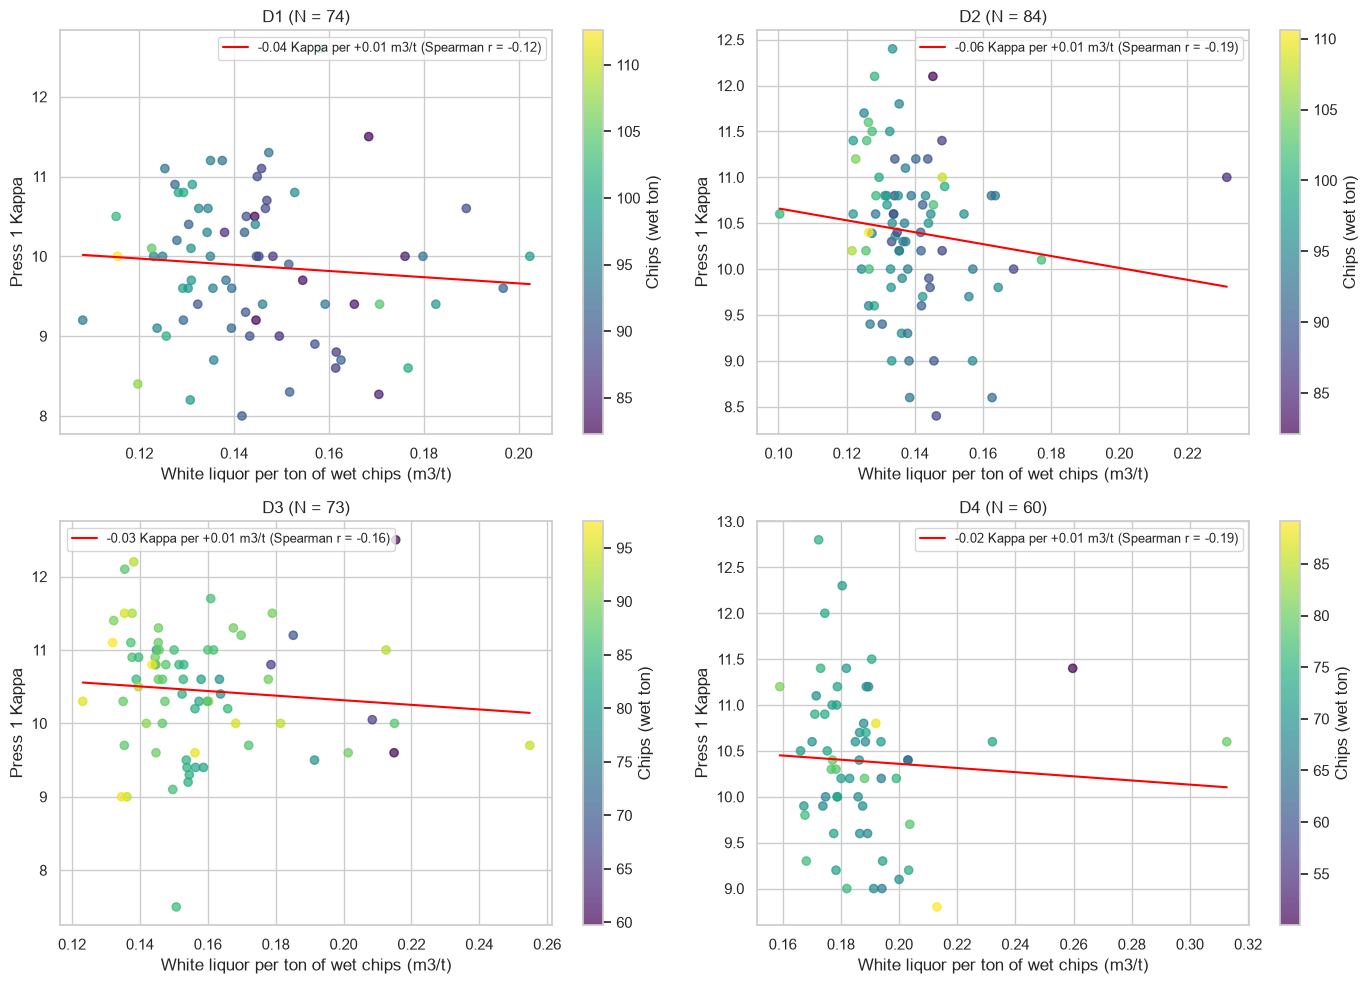

chip_weight_max_chip_filling        white_liquor_m3         \
                               median    std          median    std   
digester                                                              
1                              93.120  6.225          12.862  1.700   
2                              94.411  4.813          12.862  1.410   
3                              87.090  7.030          12.862  2.063   
4                              71.979  5.331          12.862  1.612   

         white_liquor_per_ton_chip         
                            median    std  
digester                                   
1                            0.140  0.020  
2                            0.136  0.016  
3                            0.151  0.025  
4                            0.184  0.022

digester
1   -0.01
2    0.20
3    0.20
4    0.37
Name: Spearman r: white liquor m3 vs chip weight (≈ 0 = not adjusted to chips), dtype: float64

In [10]:
wk = master.dropna(subset=["white_liquor_per_ton_chip", "press1_kappa"])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, dig in zip(axes.flatten(), [1, 2, 3, 4]):
    d = wk[wk["digester"] == dig]
    points = ax.scatter(d["white_liquor_per_ton_chip"], d["press1_kappa"], c=d["chip_weight_max_chip_filling"],
                        cmap="viridis", alpha=0.7)
    fig.colorbar(points, ax=ax, label="Chips (wet ton)")
    if len(d) >= 5:
        slope, intercept = np.polyfit(d["white_liquor_per_ton_chip"], d["press1_kappa"], 1)
        x = np.linspace(d["white_liquor_per_ton_chip"].min(), d["white_liquor_per_ton_chip"].max(), 50)
        r = d["white_liquor_per_ton_chip"].corr(d["press1_kappa"], method="spearman")
        ax.plot(x, slope * x + intercept, color="red",
                label=f"{slope * 0.01:+.2f} Kappa per +0.01 m3/t (Spearman r = {r:.2f})")
        ax.legend(fontsize=9)
    ax.set_title(f"D{dig} (N = {len(d)})")
    ax.set_xlabel("White liquor per ton of wet chips (m3/t)")
    ax.set_ylabel("Press 1 Kappa")
plt.tight_layout()
plt.show()

# Is the white liquor volume really fixed? (small SD = fixed recipe, not adjusted to the chip weight)
display(master.groupby("digester")[["chip_weight_max_chip_filling", "white_liquor_m3", "white_liquor_per_ton_chip"]]
        .agg(["median", "std"]).round(3))
display(master.groupby("digester").apply(
    lambda d: d["white_liquor_m3"].corr(d["chip_weight_max_chip_filling"], method="spearman"))
        .round(2).rename("Spearman r: white liquor m3 vs chip weight (≈ 0 = not adjusted to chips)"))
